# Data Pipeline Checks

This notebook checks the image-loading and preprocessing pipeline before
model training.

It uses the implementation in `src/fetalvision/data.py` to verify:

- image loading from the saved split CSV files;
- class-to-index mapping;
- batch shapes, dtypes and finite values;
- preprocessing and augmentation effects;
- deterministic validation preprocessing.

Patient-level split checks are documented in `02_Split_data_checks.ipynb`.

# 📚 Libraries

In [ ]:
#import pandas as pd
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from PIL import Image

from pathlib import Path
import sys

In [6]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

SRC = ROOT / "src"

print("Wanted Directory :", SRC)
assert (SRC / "fetalvision" / "data.py").is_file(), "Wrong path"

sys.path.insert(0, str(SRC))


print("Current working directory:", Path.cwd())

Wanted Directory : c:\Users\malik\Documents\AI\my_prjects\fetal_anomalies\fetal_vision\src
Current working directory: c:\Users\malik\Documents\AI\my_prjects\fetal_anomalies\fetal_vision\notebooks


## Batch Validation

Check that the sampled batch contains:

- images with shape `[8, 3, 224, 224]` and dtype `float32`;
- labels with dtype `int64` and values between 0 and 5;
- no NaN or infinite pixel values.

These checks validate the sampled batch's format. They do not establish
that every image in the dataset loads correctly or has the correct label.

In [3]:
from fetalvision.data import (
    CLASSES,
    FetalPlanesDataset,
    build_transforms,
)

train_dataset = FetalPlanesDataset(
    csv_path=ROOT / "data" / "splits" / "train.csv",
    images_dir=ROOT / "data" / "raw" / "images",
    transform=build_transforms(train=True),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
)

batch = next(iter(train_loader))

print("Dataset size:", len(train_dataset))
print("Image batch:", batch["image"].shape, batch["image"].dtype)
print("Labels:", batch["label"])
print("First two image IDs:", batch["image_id"][:2])

assert batch["image"].shape == (8, 3, 224, 224)
assert batch["image"].dtype == torch.float32
assert batch["label"].dtype == torch.int64
assert ((batch["label"] >= 0) & (batch["label"] < len(CLASSES))).all()
assert torch.isfinite(batch["image"]).all()

Dataset size: 5702
Image batch: torch.Size([8, 3, 224, 224]) torch.float32
Labels: tensor([5, 0, 1, 5, 1, 5, 4, 4])
First two image IDs: ['Patient00827_Plane1_1_of_1', 'Patient00793_Plane2_1_of_1']


## Before and After Preprocessing

Compare each original image with its transformed version from the sampled
training batch. Image IDs are used to retrieve the matching originals.

Normalization is reversed for display. The transformations are not applied
again, so the bottom row shows the exact augmented images loaded in the batch.

Inspect anatomical proportions, padding, grayscale conversion and any
loss of visible content caused by rotation.

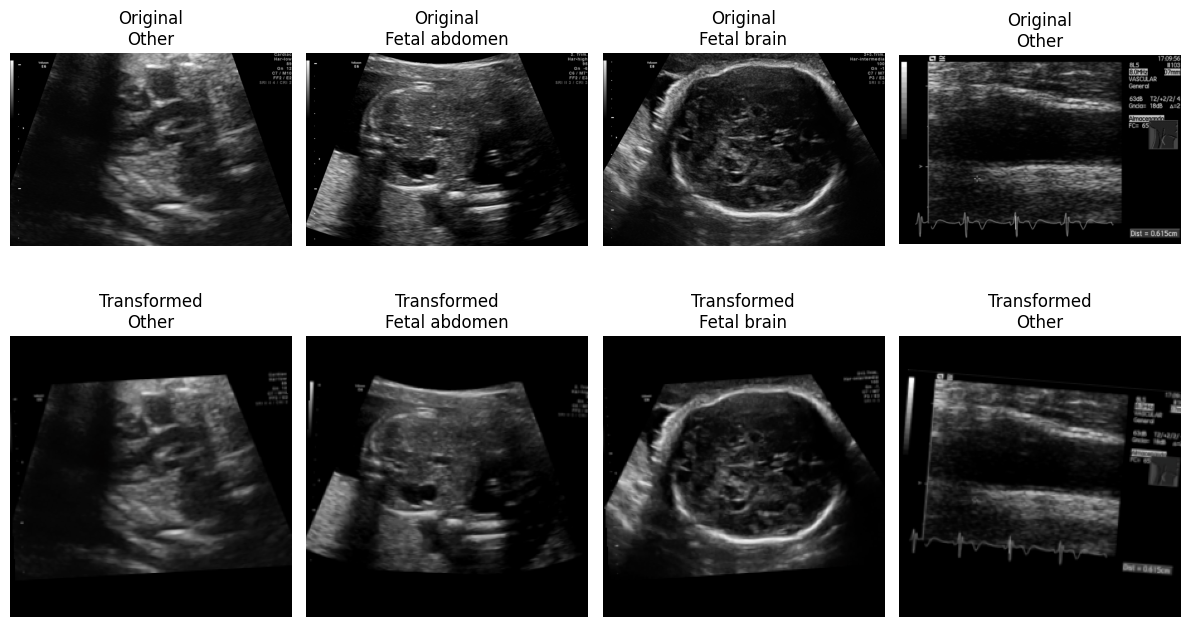

In [ ]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

n_images = min(4, len(batch["image"]))

fig, axes = plt.subplots(
    2, n_images,
    figsize=(3 * n_images, 7),
    squeeze=False,
)

for i in range(n_images):
    image_id = batch["image_id"][i]
    label = batch["label"][i].item()
    class_name = CLASSES[label]

    # Load the matching original without applying the training transforms.
    image_path = train_dataset.images_dir / f"{image_id}.png"

    with Image.open(image_path) as image:
        original = image.convert("RGB")

    # Reverse normalization on the transformed image already in the batch.
    transformed = batch["image"][i].detach().cpu()
    transformed = transformed * std + mean
    transformed = transformed.clamp(0, 1).permute(1, 2, 0).numpy()

    axes[0, i].imshow(original)
    axes[0, i].set_title(f"Original\n{class_name}")

    axes[1, i].imshow(transformed)
    axes[1, i].set_title(f"Transformed\n{class_name}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

## Deterministic Validation Preprocessing

Validation uses the same grayscale conversion, resize with padding and
normalization as training, without random augmentations.

Load the same validation sample twice and check that the resulting image
tensors are identical.

In [5]:
val_dataset = FetalPlanesDataset(
    csv_path=ROOT / "data" / "splits" / "val.csv",
    images_dir=ROOT / "data" / "raw" / "images",
    transform=build_transforms(train=False),
)

first_read = val_dataset[0]
second_read = val_dataset[0]

assert torch.equal(first_read["image"], second_read["image"]), (
    "Validation preprocessing must be deterministic."
)

print("Validation preprocessing is deterministic for the checked sample.")

Validation preprocessing is deterministic for the checked sample.


# Conclusion 🐙

- Training batch assertions passed.
- Displayed images and class labels were reviewed.
- Different image formats and aspect ratios were inspected.
- Validation preprocessing was deterministic for the checked sample.
